# 12 · Importance sampling from scratch

**Level:** intermediate · **Prerequisites:** [03](03_first_fit.ipynb) · **Run time:** ~10 s

**Covers:** importance weights, self-normalised estimates, the effective sample size, Pareto-smoothed importance sampling and k̂ (`pizzetti._sampling.psis`), the blind spot of weight diagnostics, defensive mixtures, adaptive multiple importance sampling (`pizzetti._sampling.pmc_refine`)

MCMC explores a posterior by walking through it. Importance sampling (IS) does something simpler: it draws
independent points from a distribution we *can* sample, the **proposal** q, and corrects for the difference
to the **target** p with a weight per draw. There is no burn-in and no autocorrelation, and every draw can be
evaluated in parallel. The price is that the result is only as good as the proposal.

This notebook builds the method up on one- and two-dimensional toy densities, with numpy and two helper
functions from pizzetti. Notebooks 13–16 then apply it to transit fits.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from pizzetti._sampling import psis, pmc_refine

rng = np.random.default_rng(1)

## 1. Weights

We want expectations under a target density p(x), known only up to a constant (like a posterior). We draw
x₁ … x_N from a proposal q and give each draw the weight wᵢ = p(xᵢ) / q(xᵢ). Normalising the weights to sum to
one removes the unknown constant, and any expectation becomes a weighted average:

$$E_p[f] \approx \sum_i \tilde w_i\, f(x_i), \qquad \tilde w_i = \frac{w_i}{\sum_j w_j}.$$

The target here is a skewed density, a gamma distribution with shape 3 (mean 3, standard deviation 1.73), and the
proposal a Student-t distribution with 5 degrees of freedom, centred on the target's mode. We work with
log densities throughout, as with a real posterior.

IS estimate of the mean: 3.025   (exact 3.000)
IS estimate of the sd:   1.773   (exact 1.732)


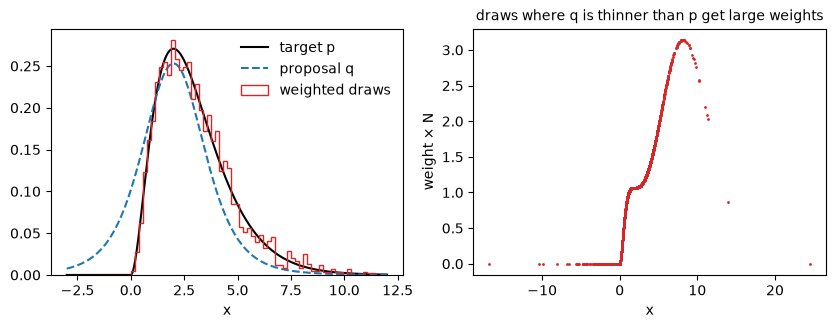

In [2]:
target = stats.gamma(3.0)                      # p(x): skewed, zero below x = 0 (like b at its wall)
def log_p(x):
    return target.logpdf(x)                    # in practice only known up to a constant

def t_proposal(loc, scale, nu=5):
    return stats.t(nu, loc=loc, scale=scale)

q = t_proposal(2.0, 1.5)
x = q.rvs(4000, random_state=rng)
logw = log_p(x) - q.logpdf(x)                  # -inf for x < 0: those draws get zero weight
w = np.exp(logw - logw.max()); w /= w.sum()

print(f"IS estimate of the mean: {np.sum(w * x):.3f}   (exact {target.mean():.3f})")
print(f"IS estimate of the sd:   {np.sqrt(np.sum(w * (x - np.sum(w * x))**2)):.3f}   (exact {target.std():.3f})")

grid = np.linspace(-3, 12, 600)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
ax[0].plot(grid, target.pdf(grid), "k", label="target p")
ax[0].plot(grid, q.pdf(grid), "C0--", label="proposal q")
ax[0].hist(x, bins=80, range=(-3, 12), weights=w / (15 / 80), histtype="step", color="C3", label="weighted draws")
ax[0].legend(frameon=False); ax[0].set_xlabel("x")
ax[1].plot(x, w * len(w), ".", ms=2, color="C3")
ax[1].set_xlabel("x"); ax[1].set_ylabel("weight × N")
ax[1].set_title("draws where q is thinner than p get large weights", fontsize=10);

## 2. How good are the weights? The effective sample size

Equal weights would make all N draws count. Unequal weights waste some of them. The **effective sample size**

$$\mathrm{ESS} = \frac{1}{\sum_i \tilde w_i^2}$$

is N for equal weights and 1 if a single draw carries all the weight. It is the number of independent draws
from p that would give the same precision. Below, the same target is sampled with proposals of different widths.

In [3]:
def is_run(q, n=4000, seed=0):
    x = q.rvs(n, random_state=np.random.default_rng(seed))
    lw_raw = log_p(x) - q.logpdf(x)
    lw, khat = psis(lw_raw)                    # Pareto-smoothed log weights (section 3) and k-hat
    w = np.exp(lw)
    return x, w, 1.0 / np.sum(w**2), khat

scales = [0.3, 0.5, 0.8, 1.2, 1.8, 2.5, 4, 6, 10]
rows = []
for s in scales:
    x, w, ess, khat = is_run(t_proposal(2.0, s))
    rows.append((s, ess / len(x), khat, np.sum(w * x)))
    print(f"proposal scale {s:5.1f}:  ESS/N {ess / len(x):5.2f}   k-hat {khat:5.2f}   mean {np.sum(w * x):.3f}")

proposal scale   0.3:  ESS/N  0.01   k-hat  0.90   mean 2.863
proposal scale   0.5:  ESS/N  0.01   k-hat  1.49   mean 3.631
proposal scale   0.8:  ESS/N  0.19   k-hat  0.70   mean 3.100
proposal scale   1.2:  ESS/N  0.63   k-hat -0.01   mean 2.959
proposal scale   1.8:  ESS/N  0.78   k-hat -1.35   mean 2.955
proposal scale   2.5:  ESS/N  0.69   k-hat -1.55   mean 2.977
proposal scale   4.0:  ESS/N  0.48   k-hat -1.55   mean 3.004
proposal scale   6.0:  ESS/N  0.33   k-hat -1.53   mean 2.995
proposal scale  10.0:  ESS/N  0.20   k-hat -1.51   mean 2.959


Too narrow a proposal (scale 0.3–0.5) misses the long right tail: a few draws there carry huge weights, the ESS
collapses and the estimate of the mean is off. Too wide a proposal wastes draws in regions of negligible target
density, so the ESS falls slowly again. In between, a proposal slightly wider than the target is efficient.

## 3. Pareto-smoothed importance sampling and k̂

The ESS is itself estimated from the draws and can be badly wrong when the weights have a heavy tail.
**Pareto-smoothed importance sampling** (PSIS; Vehtari et al. 2024) fits a generalised Pareto distribution to the
largest weights, replaces them by its quantiles (which stabilises the estimate), and reports the fitted shape k̂:

| k̂ | meaning |
|---|---|
| < 0.5 | the weights have finite variance; the estimate converges at the usual rate |
| 0.5 – 0.7 | finite mean, infinite variance: still usable with PSIS, but slow |
| > 0.7 | unreliable; more draws hardly help |

pizzetti's `psis(logw)` returns the smoothed, normalised log weights and k̂, as used above.

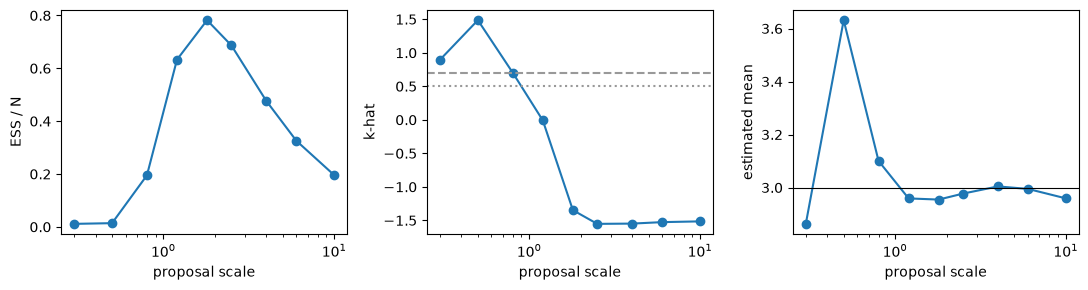

In [4]:
s_, ess_, k_, m_ = map(np.array, zip(*rows))
fig, ax = plt.subplots(1, 3, figsize=(11, 3))
ax[0].semilogx(s_, ess_, "o-"); ax[0].set_ylabel("ESS / N")
ax[1].semilogx(s_, k_, "o-"); ax[1].axhline(0.5, color="0.6", ls=":"); ax[1].axhline(0.7, color="0.6", ls="--")
ax[1].set_ylabel("k-hat")
ax[2].semilogx(s_, m_, "o-"); ax[2].axhline(target.mean(), color="k", lw=0.8); ax[2].set_ylabel("estimated mean")
for a in ax:
    a.set_xlabel("proposal scale")
fig.tight_layout()

## 4. The blind spot: what the weights cannot see

k̂ and the ESS are computed from the draws that were made. A region where the proposal puts (almost) no draws
contributes nothing to them. If the target has mass there, the estimate is wrong, and the diagnostics look
perfect.

Here the target has a second, smaller mode at x = 6 holding 10% of the mass, and the proposal, a Gaussian with
light tails, covers only the main mode.

In [5]:
def log_p2(x):                                  # 0.9 N(0, 1) + 0.1 N(6, 0.5)
    return np.logaddexp(np.log(0.9) + stats.norm(0, 1).logpdf(x), np.log(0.1) + stats.norm(6, 0.5).logpdf(x))

exact_mean = 0.9 * 0 + 0.1 * 6
q = stats.norm(0.0, 1.3)
x = q.rvs(4000, random_state=np.random.default_rng(2))
lw, khat = psis(log_p2(x) - q.logpdf(x))
w = np.exp(lw)
print(f"draws beyond x = 4: {np.sum(x > 4)} of {len(x)}")
print(f"k-hat {khat:.2f}, ESS/N {1 / np.sum(w**2) / len(x):.2f}  ->  diagnostics look fine")
print(f"estimated mean {np.sum(w * x):.3f}, exact {exact_mean:.3f}  ->  the second mode is missing")

draws beyond x = 4: 3 of 4000
k-hat 0.29, ESS/N 0.91  ->  diagnostics look fine
estimated mean -0.006, exact 0.600  ->  the second mode is missing


The first remedy is to make sure every region of the target has *some* proposal density. A **defensive
mixture** (Hesterberg 1995) adds a broad component to the proposal. Its draws in the missed region come with
large weights, so k̂ now flags the problem. The weights must be computed against the whole mixture, not against
the component a draw happened to come from.

In [6]:
narrow, broad = stats.norm(0.0, 1.3), t_proposal(0.0, 6.0)
def log_q_mix(x, f=0.1):
    return np.logaddexp(np.log(1 - f) + narrow.logpdf(x), np.log(f) + broad.logpdf(x))

r = np.random.default_rng(3)
n = 4000
nb = r.binomial(n, 0.1)
x = np.concatenate([narrow.rvs(n - nb, random_state=r), broad.rvs(nb, random_state=r)])
lw, khat = psis(log_p2(x) - log_q_mix(x))
w = np.exp(lw)
print(f"defensive mixture: draws beyond x = 4: {np.sum(x > 4)}, k-hat {khat:.2f}, ESS/N {1 / np.sum(w**2) / n:.2f}")
print(f"estimated mean {np.sum(w * x):.3f}, exact {exact_mean:.3f}  ->  still off, but now flagged")
x_def, lw_def = x, log_p2(x) - log_q_mix(x)      # kept for section 5

defensive mixture: draws beyond x = 4: 100, k-hat 3.06, ESS/N 0.56
estimated mean 0.312, exact 0.600  ->  still off, but now flagged


## 5. Adaptive importance sampling

A proposal does not have to be fixed. **Adaptive multiple importance sampling** (AMIS; Cornuet et al. 2012)
fits a new proposal (here a mixture of Student-t components) to all weighted draws so far, draws from it, and
weights *all* draws against the mixture of *all* proposals used (deterministic-mixture weights). Each iteration
moves proposal density to where the target has mass. pizzetti's `pmc_refine` does this, and stops once
k̂ < 0.7, the ESS is large enough and the quantiles no longer move. Started from the defensive draws of
section 4, it finds the second mode:

In [7]:
res = pmc_refine(lambda X: log_p2(np.atleast_2d(X)[:, 0]), x_def[:, None], lw_def, np.random.default_rng(3),
                 n=4000, iters=15, min_iters=3)
for i, h in enumerate(res["history"]):
    print(f"iteration {i + 1}: k-hat {h['khat']:5.2f}   ESS {h['ess']:6.0f} of {h['n']} draws")
print(f"estimated mean {np.sum(res['w'] * res['theta'][:, 0]):.3f}, exact {exact_mean:.3f}")

iteration 1: k-hat -1.65   ESS   3275 of 4000 draws
iteration 2: k-hat -1.74   ESS   6597 of 8000 draws
iteration 3: k-hat -1.72   ESS   9936 of 12000 draws
estimated mean 0.605, exact 0.600


`pmc_refine`'s `extra` components stay in every iteration; a broad one over the whole region of interest keeps
the estimate consistent whatever the start missed. The target below is a curved ridge in two dimensions, similar to the b–a/R★ degeneracy of a transit
(notebook 13), with a hard wall at x = 0. The start is a few hundred draws from a small Gaussian at the top
of the ridge.

iteration 1: k-hat  1.07   ESS      69 of 2000 draws   quantile change inf sd
iteration 2: k-hat  0.97   ESS     562 of 4000 draws   quantile change 2.545 sd
iteration 3: k-hat  0.32   ESS    3251 of 6000 draws   quantile change 0.132 sd
iteration 4: k-hat -0.18   ESS    4993 of 8000 draws   quantile change 0.032 sd
converged: True


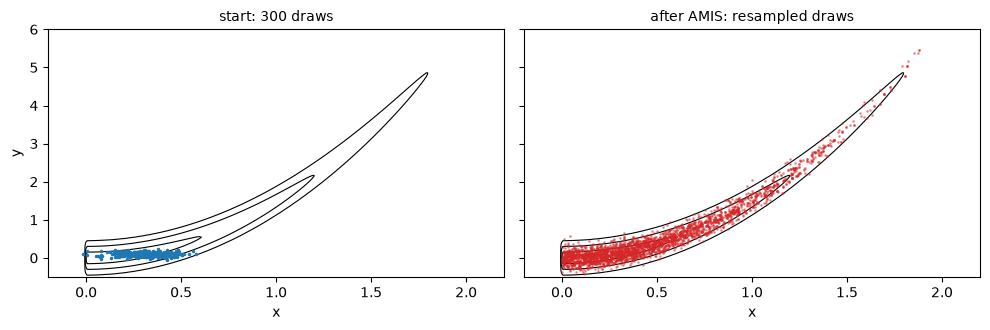

In [8]:
def log_p3(X):
    X = np.atleast_2d(X)
    x, y = X[:, 0], X[:, 1]
    out = -0.5 * (x / 0.6)**2 - 0.5 * ((y - 1.5 * x**2) / 0.15)**2     # curved ridge y ~ 1.5 x^2
    return np.where(x >= 0, out, -np.inf)                               # wall at x = 0

r = np.random.default_rng(4)
X0 = r.normal([0.3, 0.1], [0.1, 0.05], size=(300, 2))
lw0 = log_p3(X0) - stats.multivariate_normal([0.3, 0.1], np.diag([0.1, 0.05])**2).logpdf(X0)
box = (0.05, np.array([1.0, 1.0]), np.diag([2.0, 3.0])**2)             # a broad defensive component
res = pmc_refine(log_p3, X0, lw0, r, n=2000, iters=12, min_iters=3, extra=[box])
for i, h in enumerate(res["history"]):
    print(f"iteration {i + 1}: k-hat {h['khat']:5.2f}   ESS {h['ess']:7.0f} of {h['n']} draws   "
          f"quantile change {h.get('dq', float('nan')):.3f} sd")
print("converged:", res["converged"])

Xs, ws = res["theta"], res["w"]
gx, gy = np.meshgrid(np.linspace(-0.2, 2.2, 200), np.linspace(-0.5, 6, 200))
lp = log_p3(np.column_stack([gx.ravel(), gy.ravel()])).reshape(gx.shape)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4), sharey=True)
for a in ax:
    a.contour(gx, gy, np.exp(lp - np.nanmax(lp)), levels=[0.011, 0.135, 0.6], colors="k", linewidths=0.8)
ax[0].plot(X0[:, 0], X0[:, 1], ".", ms=3, color="C0"); ax[0].set_title("start: 300 draws", fontsize=10)
keep = r.choice(len(Xs), 3000, p=ws, replace=True)
ax[1].plot(Xs[keep, 0], Xs[keep, 1], ".", ms=2, color="C3", alpha=0.4)
ax[1].set_title("after AMIS: resampled draws", fontsize=10)
for a in ax:
    a.set_xlabel("x")
ax[0].set_ylabel("y")
fig.tight_layout()

## How this carries over to transit fits

pizzetti's `MarginalTransitModel.fit()` uses all of these ideas on the posterior of the transit geometry:

- the proposal is built along a profile of the impact parameter b, which follows the curved b–a/R★ ridge and the
  wall at b = 0 ([13](13_why_b_is_hard.ipynb), [14](14_profile_importance_sampling.ipynb));
- the weights are Pareto-smoothed, and a profile proposal is accepted only for k̂ < 0.5 and an ESS of at least
  25% of the draws;
- 10% of the draws come from a broad defensive component;
- where the profile is not enough, adaptive importance sampling with a component over the whole prior box takes
  over ([15](15_when_the_profile_is_not_enough.ipynb)).

## What you learned

- Importance sampling weights independent draws from a proposal by p/q; normalised weights remove the unknown constant.
- The ESS and the Pareto k̂ say how well the proposal matches the target *where it put draws*.
- A region the proposal misses is invisible to both: defensive components make it visible, adaptive IS fills it.

**Next:** [12 · Why b is hard](13_why_b_is_hard.ipynb)